# Pronóstico de pasajeros de aerolíneas

En este notebook analizaremos una serie mensual de pasajeros y prepararemos los datos para construir modelos de pronóstico. Compararemos sus predicciones utilizando un periodo de prueba separado cronológicamente.

## 1. Preparación del entorno

Importamos las herramientas que utilizaremos:

- **NumPy:** operaciones numéricas y manejo de arreglos.
- **pandas:** organización de los datos y manejo de fechas.
- **Matplotlib:** visualización de la serie y los pronósticos.
- **MLPRegressor:** red neuronal para problemas de regresión.
- **LinearRegression:** modelo de regresión lineal.

También establecemos el tamaño predeterminado de las gráficas.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression
plt.rcParams['figure.figsize'] = (10, 4)

Las librerías quedaron disponibles para el análisis. La regresión lineal y la red neuronal se importaron, pero todavía no se han entrenado.

## 2. Carga y exploración de la serie temporal

Utilizamos el conjunto de datos `flights` de Seaborn, que contiene el número mensual de pasajeros de aerolíneas internacionales entre **1949 y 1960**, expresado en miles.

Construimos una serie de pandas llamada `y` con un índice de fechas mensuales. La frecuencia `MS` indica que cada fecha corresponde al primer día del mes.

Antes de graficar, verificamos mediante `assert` que la serie tenga **144 observaciones** y que la suma de sus valores sea **40,363**. Esta comprobación ayuda a confirmar que cargamos los datos esperados.

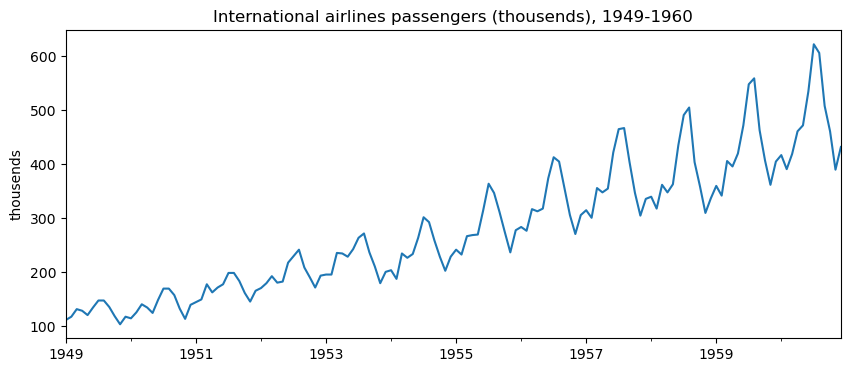

In [3]:
import seaborn as sns
flights = sns.load_dataset('flights')
y = pd.Series(flights['passengers'].values,
              index=pd.date_range('1949-01-01', periods = 144, freq = 'MS'), name='passengers')
assert len(y) == 144 and y.sum() == 40363
y.plot(title = 'International airlines passengers (thousends), 1949-1960'); plt.ylabel('thousends');plt.show()

La gráfica permite identificar dos características principales:

- **Tendencia creciente:** el número de pasajeros aumenta a lo largo de los años.
- **Estacionalidad anual:** aparecen patrones de aumentos y disminuciones que se repiten aproximadamente cada 12 meses.

Además, las fluctuaciones estacionales son mayores cuando aumenta el nivel de la serie. Esto será relevante al evaluar qué tan bien los modelos representan su comportamiento.

## 3. Separación en entrenamiento y prueba

Dividimos la serie respetando el orden temporal:

- **Entrenamiento:** enero de 1949 a diciembre de 1958, con 120 meses.
- **Prueba:** enero de 1959 a diciembre de 1960, con 24 meses.

El conjunto de entrenamiento se utilizará para ajustar los modelos. El conjunto de prueba permitirá evaluar sus pronósticos sobre meses que no participaron en el ajuste.

La variable `H` representa el horizonte de pronóstico: **24 meses**.

### Métricas de evaluación

Utilizaremos dos medidas de error:

**RMSE — raíz del error cuadrático medio**

$$
\mathrm{RMSE}=
\sqrt{\frac{1}{n}\sum_{i=1}^{n}(\hat{y}_i-y_i)^2}
$$

Mide el error en las mismas unidades de la serie: miles de pasajeros. Al elevar los errores al cuadrado, penaliza especialmente los errores grandes.

**MAPE — error porcentual absoluto medio**

$$
\mathrm{MAPE}=
\frac{100}{n}\sum_{i=1}^{n}
\left|\frac{\hat{y}_i-y_i}{y_i}\right|
$$

Expresa el error como porcentaje del valor real. Su cálculo requiere valores reales distintos de cero, condición que cumple esta serie.

En ambas métricas, **un valor menor indica un mejor pronóstico**. Guardaremos los resultados de cada modelo en el diccionario `results`.

In [4]:
train, test = y[:'1958'], y['1959':]
H = len(test)                                # forecast horizon: 24 months
print(f'train: {len(train)} months ({train.index[0]:%b %Y} - {train.index[-1]:%b %Y})')
print(f'test : {len(test)} months ({test.index[0]:%b %Y} - {test.index[-1]:%b %Y})')
print(f'max passengers in train: {train.max()}   max in test: {test.max()}')

def rmse(f, a): return float(np.sqrt(np.mean((np.asarray(f, float) - np.asarray(a, float)) ** 2)))
def mape(f, a): return float(100 * np.mean(np.abs((np.asarray(f, float) - np.asarray(a, float)) / np.asarray(a, float))))
results = {}

train: 120 months (Jan 1949 - Dec 1958)
test : 24 months (Jan 1959 - Dec 1960)
max passengers in train: 505   max in test: 622


In [5]:
snaive = np.tile(train.values[-12:], 2)
results['Seasonal naive'] = (rmse(snaive, test), mape(snaive, test))
print('Seasonal naive RMSE %.1f MAPE %.1f%%' % results['Seasonal naive'])

Seasonal naive RMSE 77.0 MAPE 15.5%


In [6]:
def make_windows(s, p):
    s = np.asarray(s, float)
    X = np.array([s[i - p:i] for i in range(p, len(s))])
    return X, s[p:]

def recursive_forecast(model, history, p, h):
    hist = list(np.asarray(history, float))
    out = []
    for _ in range(h):
        nxt = float(model.predict(np.array(hist[-p:]).reshape(1, -1))[0])
        out.append(nxt); hist.append(nxt)
    return np.array(out)

X_demo, t_demo = make_windows(np.arange(1, 8), 3)
print(X_demo, t_demo)

[[1. 2. 3.]
 [2. 3. 4.]
 [3. 4. 5.]
 [4. 5. 6.]] [4. 5. 6. 7.]


El ejemplo utiliza la secuencia del 1 al 7 con ventanas de tres valores. El resultado es:

| Entrada | Valor objetivo |
|---|---:|
| [1, 2, 3] | 4 |
| [2, 3, 4] | 5 |
| [3, 4, 5] | 6 |
| [4, 5, 6] | 7 |

Esto confirma que cada ventana queda asociada con el valor que le sigue.

La función de pronóstico recursivo quedó definida, pero todavía no se ha utilizado con un modelo entrenado. Cuando se aplique, los errores podrán acumularse, porque las predicciones anteriores alimentarán los pronósticos siguientes.

## 6. Red neuronal sobre la serie en escala logarítmica

Entrenaremos una red neuronal para predecir el número de pasajeros utilizando los **12 meses anteriores** como entrada.

### Transformación y preparación de los datos

Primero aplicamos el logaritmo natural a la serie:

$$
L_t = \ln(y_t)
$$

Esta transformación ayuda a reducir las diferencias de escala y a moderar el aumento de las fluctuaciones estacionales.

Después estandarizamos los valores utilizando únicamente la media y la desviación estándar del conjunto de entrenamiento:

$$
z_t = \frac{L_t-m}{s}
$$

Aunque se calcula el logaritmo de toda la serie, el ajuste del escalamiento y el entrenamiento utilizan solamente los primeros 120 meses. Así evitamos incorporar información del periodo de prueba al ajuste.

### Configuración de la red neuronal

Utilizamos `MLPRegressor` con:

- **12 entradas:** los valores de los 12 meses anteriores.
- **Una capa oculta de 32 neuronas.**
- **Activación ReLU:** permite representar relaciones no lineales.
- **Regularización L2 (`alpha = 0.001`):** penaliza los pesos grandes.
- **Hasta 5,000 iteraciones de entrenamiento.**
- **Semilla fija (`random_state = 0`):** facilita reproducir el resultado.

Los hiperparámetros se fijan previamente, sin ajustarlos con los resultados del conjunto de prueba.

### Generación del pronóstico

La red genera los siguientes **24 meses de forma recursiva**: cada predicción se incorpora al historial para calcular la siguiente.

Finalmente, deshacemos la estandarización y aplicamos la función exponencial para regresar a miles de pasajeros:

$$
\hat{y}_t = \exp(s\hat{z}_t+m)
$$

Evaluamos el pronóstico con RMSE y MAPE, y lo graficamos junto con los datos reales y el modelo estacional ingenuo.

MLP on log levels RMSE 113.9 MAPE 20.0%
Highest scaled input seen in training: 2.04; scaled log of Jul 1960: 2.57


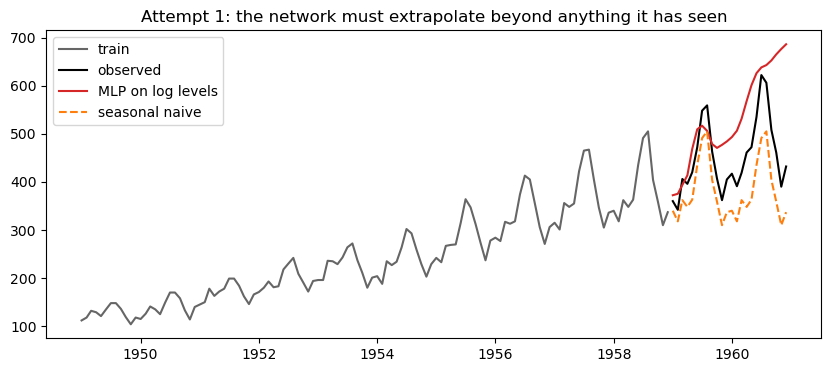

In [7]:
p = 12
L = np.log(y.values)  # Logaritmos de los 144 meses
Ltr = L[:len(train)]
m, s = Ltr.mean(), Ltr.std()  # Estadísticas de entrenamiento
Xtr, ttr = make_windows((Ltr - m) / s, p)

mlp_levels = MLPRegressor(
    hidden_layer_sizes=(32,),
    activation='relu',
    alpha=1e-3,
    max_iter=5000,
    random_state=0
)

mlp_levels.fit(Xtr, ttr)

f_scaled = recursive_forecast(
    mlp_levels, (Ltr - m) / s, p, H
)
f_levels = np.exp(f_scaled * s + m)

results['MLP on log levels'] = (
    rmse(f_levels, test),
    mape(f_levels, test)
)

print(
    'MLP on log levels RMSE %.1f MAPE %.1f%%'
    % results['MLP on log levels']
)
print(
    f'Highest scaled input seen in training: {Xtr.max():.2f}; '
    f'scaled log of Jul 1960: {(L[-6] - m) / s:.2f}'
)

plt.plot(train.index, train, color='0.4', label='train')
plt.plot(test.index, test, 'k', label='observed')
plt.plot(
    test.index, f_levels, 'C3',
    label='MLP on log levels'
)
plt.plot(
    test.index, snaive, 'C1--',
    label='seasonal naive'
)
plt.legend()
plt.title(
    'Attempt 1: the network must extrapolate beyond anything it has seen'
)
plt.show()

### Resultados e interpretación

La red neuronal obtuvo los siguientes resultados en el periodo de prueba:

| Modelo | RMSE (miles de pasajeros) | MAPE |
|---|---:|---:|
| Estacional ingenuo | 77.0 | 15.5 % |
| Red neuronal sobre logaritmos | 113.9 | 20.0 % |

En este experimento, la red neuronal presenta errores mayores que el modelo estacional ingenuo. Por tanto, su mayor complejidad no se tradujo en un mejor pronóstico.

El código también compara la escala de los datos:

- El mayor valor estandarizado presente en las entradas de entrenamiento fue **2.04**.
- El valor real de julio de 1960, transformado con la misma media y desviación estándar, fue **2.57**.

Esto muestra que el periodo de prueba incluye niveles superiores a los observados en las entradas de entrenamiento. La red necesita **extrapolar**, es decir, predecir fuera del rango con el que aprendió.

Además, el pronóstico recursivo puede acumular errores, porque utiliza sus propias predicciones para generar los meses posteriores.

Estos resultados indican que esta configuración de la red no logró superar la referencia estacional; por sí solos, no permiten atribuir el error a una única causa.

## 7. Segundo intento: red neuronal sobre la serie transformada

En este intento buscamos reducir la tendencia y la estacionalidad antes de entrenar la red neuronal.

Aplicamos una diferencia mensual y una diferencia estacional de 12 meses sobre los logaritmos:

$$
z_t = (L_t-L_{t-12})-(L_{t-1}-L_{t-13}),
\qquad L_t=\ln(y_t)
$$

Equivalentemente:

$$
z_t=L_t-L_{t-1}-L_{t-12}+L_{t-13}
$$

Esta transformación representa el cambio mensual en la diferencia entre el nivel logarítmico actual y el de un año antes. Su objetivo es obtener una serie más estable; la transformación por sí sola no garantiza estacionariedad.

### Preparación y entrenamiento

1. Calculamos la serie transformada usando únicamente el entrenamiento.
2. La estandarizamos con su propia media y desviación estándar.
3. Construimos ventanas de **13 valores anteriores** para predecir el siguiente.
4. Entrenamos una red con una capa oculta de **32 neuronas ReLU**.
5. Generamos un pronóstico recursivo de **24 meses**.

### Reconstrucción de los pasajeros

La función `undo` deshace las diferencias mes a mes:

$$
\widehat{L}_t
=
\widehat{z}_t+L_{t-1}+L_{t-12}-L_{t-13}
$$

Cuando los valores anteriores corresponden al futuro, utilizamos los que ya reconstruimos. Finalmente, aplicamos la exponencial para regresar a miles de pasajeros y calculamos RMSE y MAPE.

In [8]:
def z_of(Lser):
    # (1 - B)(1 - B^12) log y, definido desde t = 13
    Lser = np.asarray(Lser, float)
    return (
        Lser[13:]
        - Lser[12:-1]
        - Lser[1:-12]
        + Lser[:-13]
    )


def undo(z_future, L_hist):
    """Reconstruye los logaritmos a partir del pronóstico y el historial."""
    Lh = list(L_hist)

    for zt in z_future:
        Lh.append(zt + Lh[-1] + Lh[-12] - Lh[-13])

    return np.array(Lh[len(L_hist):])


p = 13
ztr = z_of(Ltr)  # 107 valores, solo del entrenamiento
mz, sz = ztr.mean(), ztr.std()

Xz, tz = make_windows((ztr - mz) / sz, p)
print('training windows:', Xz.shape)


def mlp_forecast(seed):
    net = MLPRegressor(
        hidden_layer_sizes=(32,),
        activation='relu',
        alpha=1e-3,
        max_iter=5000,
        random_state=seed
    )

    net.fit(Xz, tz)

    zf = recursive_forecast(
        net,
        (ztr - mz) / sz,
        p,
        H
    ) * sz + mz

    return np.exp(undo(zf, Ltr))


f_mlp = mlp_forecast(0)

results['MLP transform'] = (
    rmse(f_mlp, test),
    mape(f_mlp, test)
)

print(
    'MLP transform RMSE %.1f MAPE %.1f%%'
    % results['MLP transform']
)

training windows: (94, 13)
MLP transform RMSE 80.1 MAPE 15.1%


### Interpretación del procedimiento

Al aplicar las diferencias a los **120 meses de entrenamiento**, obtenemos **107 valores transformados**, porque necesitamos 13 observaciones previas para calcular el primero.

Con ventanas de 13 valores generamos **94 ejemplos de entrenamiento**. Por ello, `Xz.shape` debe mostrar:

`(94, 13)`

La red aprende a predecir la serie transformada. Después, reconstruimos los niveles logarítmicos y los convertimos a miles de pasajeros.

Las métricas impresas evalúan el pronóstico en la escala original. Para superar al modelo estacional ingenuo, este intento debe obtener un **RMSE menor que 77.0** y un **MAPE menor que 15.5 %**.

Aunque la transformación busca facilitar el aprendizaje, el pronóstico sigue siendo recursivo y puede acumular errores. Debemos revisar las métricas obtenidas antes de concluir si este segundo intento mejora los resultados.

### Resultados de la red sobre la serie transformada

Se generaron **94 ventanas de entrenamiento**, cada una con **13 entradas**.

La red obtuvo un **RMSE de 80.1 mil pasajeros** y un **MAPE de 15.1 %**.

La transformación mejoró ambos indicadores respecto a la red entrenada directamente sobre los logaritmos. Frente al modelo estacional ingenuo, el resultado es mixto: reduce el MAPE de 15.5 % a 15.1 %, pero aumenta el RMSE de 77.0 a 80.1.

Por tanto, este intento no supera a la referencia en ambas métricas.

## 8. Regresión lineal sobre la serie transformada

Para comparar con la red neuronal, entrenamos una regresión lineal utilizando las mismas ventanas de **13 valores anteriores** de la serie transformada y estandarizada.

Este modelo funciona como una autorregresión de orden 13 sobre esa transformación: predice el siguiente valor mediante una combinación lineal de los 13 anteriores.

$$
\widehat{u}_t=b+\sum_{j=1}^{13}w_j u_{t-j}
$$

Aquí, $u_t$ representa la serie transformada y estandarizada.

Generamos los 24 pronósticos de forma recursiva, deshacemos la estandarización y reconstruimos los logaritmos con `undo`. Finalmente, aplicamos la exponencial para regresar a miles de pasajeros.

La gráfica compara los datos reales con los pronósticos de la red neuronal, la regresión lineal y el método estacional ingenuo. Todos los pronósticos parten del cierre de diciembre de 1958.

Linear AR(13) RMSE 67.6 MAPE 13.2%


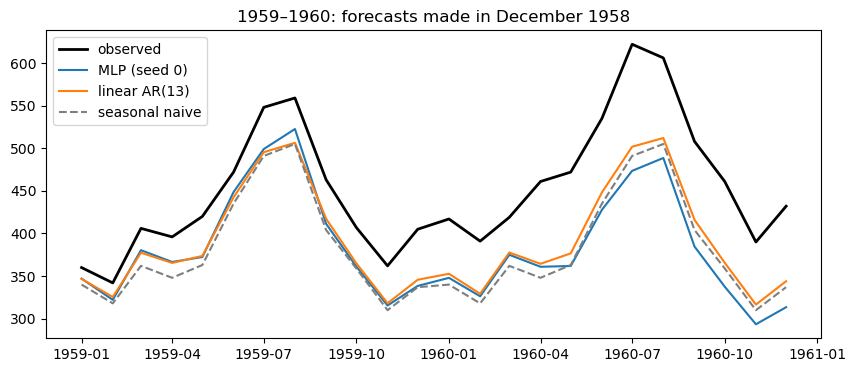

In [9]:
lin = LinearRegression().fit(Xz, tz)

zf_lin = recursive_forecast(
    lin, (ztr - mz) / sz, p, H
) * sz + mz

f_lin = np.exp(undo(zf_lin, Ltr))

results['Linear AR(13) on Class 7 transform'] = (
    rmse(f_lin, test),
    mape(f_lin, test)
)

print(
    'Linear AR(13) RMSE %.1f MAPE %.1f%%'
    % results['Linear AR(13) on Class 7 transform']
)

plt.plot(
    test.index, test, 'k',
    lw=2, label='observed'
)
plt.plot(
    test.index, f_mlp, 'C0',
    label='MLP (seed 0)'
)
plt.plot(
    test.index, f_lin, 'C1',
    label='linear AR(13)'
)
plt.plot(
    test.index, snaive, 'C7--',
    label='seasonal naive'
)

plt.legend()
plt.title('1959–1960: forecasts made in December 1958')
plt.show()

### Comparación de resultados

| Modelo | RMSE (miles de pasajeros) | MAPE |
|---|---:|---:|
| Estacional ingenuo | 77.0 | 15.5 % |
| Red neuronal sobre logaritmos | 113.9 | 20.0 % |
| Red neuronal sobre la serie transformada | 80.1 | 15.1 % |
| Regresión lineal sobre la serie transformada | 67.6 | 13.2 % |

La regresión lineal sobre la serie transformada obtiene el menor error en ambas métricas para este periodo de prueba.

La transformación permitió mejorar el desempeño de la red neuronal, pero el modelo lineal logró mejores resultados utilizando las mismas entradas.

Este experimento muestra que una mayor complejidad no garantiza mejores pronósticos. La preparación de la serie y la comparación con modelos sencillos son fundamentales para evaluar el beneficio de una red neuronal.

La conclusión corresponde a este periodo de prueba y a las configuraciones utilizadas; no implica que la regresión lineal siempre sea superior.

## 9. Variabilidad de la red y ensamble de diez modelos

El entrenamiento de una red neuronal incluye componentes aleatorios, como los pesos iniciales. Por ello, cambiar la semilla puede producir pronósticos diferentes, incluso utilizando los mismos datos y la misma arquitectura.

Entrenamos **diez redes**, con semillas de 0 a 9, y calculamos el RMSE y el MAPE de cada una. Después mostramos el mínimo, la mediana y el máximo de cada métrica para evaluar cuánto varía el desempeño.

### Construcción del ensamble

Combinamos los diez pronósticos promediando sus logaritmos y aplicando después la exponencial:

$$
\widehat{y}^{ens}_t
=
\exp\left(
\frac{1}{10}\sum_{k=1}^{10}\ln(\widehat{y}^{(k)}_t)
\right)
$$

Esto equivale a calcular la **media geométrica** de los pronósticos de cada mes.

El objetivo es reducir la dependencia de una sola ejecución. La gráfica muestra los diez pronósticos individuales, el ensamble y los valores reales.

RMSE over 10 seeds: min 31.4 median 64.1 max 102.3
MAPE over 10 seeds: min 5.7% median 12.1% max 19.9%
MLP ensemble RMSE 67.5 MAPE 13.0%


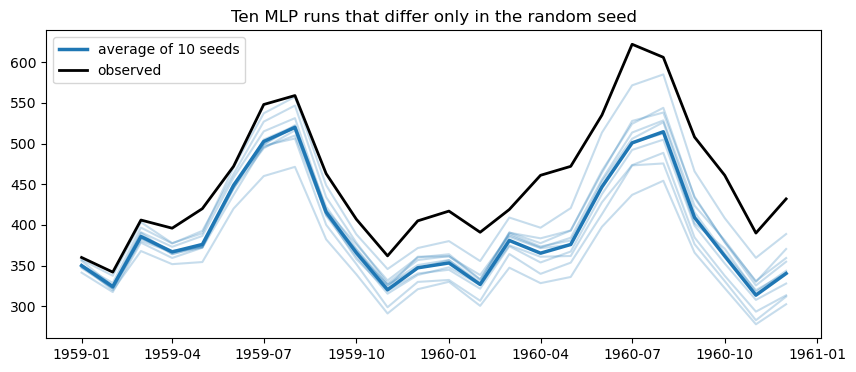

In [10]:
runs = np.array([
    mlp_forecast(seed) for seed in range(10)
])

r_rmse = [rmse(f, test) for f in runs]
r_mape = [mape(f, test) for f in runs]

print(
    'RMSE over 10 seeds: min %.1f median %.1f max %.1f'
    % (min(r_rmse), np.median(r_rmse), max(r_rmse))
)

print(
    'MAPE over 10 seeds: min %.1f%% median %.1f%% max %.1f%%'
    % (min(r_mape), np.median(r_mape), max(r_mape))
)

# Promedio en escala logarítmica
f_ens = np.exp(np.log(runs).mean(0))

results['MLP, average of 10 seeds'] = (
    rmse(f_ens, test),
    mape(f_ens, test)
)

print(
    'MLP ensemble RMSE %.1f MAPE %.1f%%'
    % results['MLP, average of 10 seeds']
)

plt.plot(
    test.index, runs.T,
    color='C0', alpha=.25
)
plt.plot(
    test.index, f_ens, 'C0',
    lw=2.5, label='average of 10 seeds'
)
plt.plot(
    test.index, test, 'k',
    lw=2, label='observed'
)

plt.legend()
plt.title('Ten MLP runs that differ only in the random seed')
plt.show()

runs = np.array([
    mlp_forecast(seed) for seed in range(10)
])

r_rmse = [rmse(f, test) for f in runs]
r_mape = [mape(f, test) for f in runs]

print(
    'RMSE over 10 seeds: min %.1f median %.1f max %.1f'
    % (min(r_rmse), np.median(r_rmse), max(r_rmse))
)

print(
    'MAPE over 10 seeds: min %.1f%% median %.1f%% max %.1f%%'
    % (min(r_mape), np.median(r_mape), max(r_mape))
)

# Promedio en escala logarítmica
f_ens = np.exp(np.log(runs).mean(0))

results['MLP, average of 10 seeds'] = (
    rmse(f_ens, test),
    mape(f_ens, test)
)

print(
    'MLP ensemble RMSE %.1f MAPE %.1f%%'
    % results['MLP, average of 10 seeds']
)

plt.plot(
    test.index, runs.T,
    color='C0', alpha=.25
)
plt.plot(
    test.index, f_ens, 'C0',
    lw=2.5, label='average of 10 seeds'
)
plt.plot(
    test.index, test, 'k',
    lw=2, label='observed'
)

plt.legend()
plt.title('Ten MLP runs that differ only in the random seed')
plt.show()

In [13]:
table =pd.DataFrame(results, index=['RMSE', 'MAPE']).T.round(1)
table

,RMSE,MAPE
Seasonal naive,77.0,15.5
MLP on log levels,113.9,20.0
MLP transform,80.1,15.1
Linear AR(13) on Class 7 transform,67.6,13.2
"MLP, average of 10 seeds",67.5,13.0
